# Lab 2 — Partie 2 : Vision Transformer (ViT) sur MNIST

## Objectif

Construire et évaluer un Vision Transformer (ViT) pour classifier les chiffres de MNIST. Le code reprend le fichier `vit_torch.py` fourni et suit son architecture et ses hyperparamètres. Les cellules sont organisées pour présenter la démarche comme un rapport.

Les étapes pédagogiques s’appuient sur le [tutoriel ViT de Brian Pulfer](https://medium.com/@brianpulfer/vision-transformers-from-scratch-pytorch-a-step-by-step-guide-96c3313c2e0c).

**Kaggle :** sélectionnez un GPU dans *Settings → Accelerator*. Le notebook conserve le modèle et la boucle d’entraînement d’origine. Les seules adaptations d’exécution Kaggle sont le chemin des données (`/kaggle/working/datasets`) et la création des patches sur le même appareil que les images (CPU ou GPU).


## 1. Imports et reproductibilité
Importer PyTorch, torchvision et les utilitaires de progression. Les graines aléatoires sont fixées comme dans le fichier fourni.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.nn import CrossEntropyLoss
from torch.optim import Adam
from torch.utils.data import DataLoader
from torchvision.datasets.mnist import MNIST
from torchvision.transforms import ToTensor
from tqdm import tqdm, trange

np.random.seed(0)
torch.manual_seed(0)


## 2. Découpage de l’image en patches
La fonction découpe chaque image en une grille de patches non chevauchants. Avec MNIST 28×28 et 7 patches par côté, chaque image devient une séquence de 49 patches de 4×4 pixels. Le découpage est vectorisé pour éviter les boucles par image et mieux exploiter le GPU.


In [2]:
def patchify(images, n_patches):
    n, c, h, w = images.shape

    assert h == w, "Patchify method is implemented for square images only"
    assert h % n_patches == 0, "Image dimensions must be divisible by n_patches"

    patch_size = h // n_patches
    patches = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
    return patches.reshape(n, n_patches**2, -1)


## 3. Attention multi-têtes
`MyMSA` conserve les projections Q, K et V séparées par tête, mais calcule les sorties pour tout le mini-lot simultanément. Cette vectorisation conserve le calcul d’attention du modèle et réduit les boucles Python.


In [3]:
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super(MyMSA, self).__init__()
        self.d = d
        self.n_heads = n_heads

        assert d % n_heads == 0, f"Can't divide dimension {d} into {n_heads} heads"

        d_head = int(d / n_heads)
        self.q_mappings = nn.ModuleList(
            [nn.Linear(d_head, d_head) for _ in range(self.n_heads)]
        )
        self.k_mappings = nn.ModuleList(
            [nn.Linear(d_head, d_head) for _ in range(self.n_heads)]
        )
        self.v_mappings = nn.ModuleList(
            [nn.Linear(d_head, d_head) for _ in range(self.n_heads)]
        )
        self.d_head = d_head
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, sequences):
        # sequences: (batch, sequence_length, token_dim)
        head_results = []
        for head in range(self.n_heads):
            start = head * self.d_head
            end = (head + 1) * self.d_head
            seq = sequences[:, :, start:end]
            q = self.q_mappings[head](seq)
            k = self.k_mappings[head](seq)
            v = self.v_mappings[head](seq)
            attention = self.softmax(q @ k.transpose(-2, -1) / (self.d_head ** 0.5))
            head_results.append(attention @ v)
        return torch.cat(head_results, dim=-1)


## 4. Bloc encodeur Transformer
Le bloc combine l’attention multi-têtes et un MLP, avec normalisation et connexions résiduelles.

In [4]:
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super(MyViTBlock, self).__init__()
        self.hidden_d = hidden_d
        self.n_heads = n_heads

        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d),
        )

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        out = out + self.mlp(self.norm2(out))
        return out


## 5. Modèle ViT
`MyViT` transforme les patches en tokens, ajoute le token de classification et les positions, applique les blocs Transformer, puis prédit l’une des dix classes.

In [5]:
class MyViT(nn.Module):
    def __init__(self, chw, n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10):
        # Super constructor
        super(MyViT, self).__init__()

        # Attributes
        self.chw = chw  # ( C , H , W )
        self.n_patches = n_patches
        self.n_blocks = n_blocks
        self.n_heads = n_heads
        self.hidden_d = hidden_d

        # Input and patches sizes
        assert (
            chw[1] % n_patches == 0
        ), "Input shape not entirely divisible by number of patches"
        assert (
            chw[2] % n_patches == 0
        ), "Input shape not entirely divisible by number of patches"
        self.patch_size = (chw[1] / n_patches, chw[2] / n_patches)

        # 1) Linear mapper
        self.input_d = int(chw[0] * self.patch_size[0] * self.patch_size[1])
        self.linear_mapper = nn.Linear(self.input_d, self.hidden_d)

        # 2) Learnable classification token
        self.class_token = nn.Parameter(torch.rand(1, self.hidden_d))

        # 3) Positional embedding
        self.register_buffer(
            "positional_embeddings",
            get_positional_embeddings(n_patches**2 + 1, hidden_d),
            persistent=False,
        )

        # 4) Transformer encoder blocks
        self.blocks = nn.ModuleList(
            [MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)]
        )

        # 5) Classification MLPk
        self.mlp = nn.Linear(self.hidden_d, out_d)

    def forward(self, images):
        # Dividing images into patches
        n, c, h, w = images.shape
        patches = patchify(images, self.n_patches).to(self.positional_embeddings.device)

        # Running linear layer tokenization
        # Map the vector corresponding to each patch to the hidden size dimension
        tokens = self.linear_mapper(patches)

        # Adding classification token to the tokens
        tokens = torch.cat((self.class_token.expand(n, 1, -1), tokens), dim=1)

        # Adding positional embedding
        out = tokens + self.positional_embeddings.repeat(n, 1, 1)

        # Transformer Blocks
        for block in self.blocks:
            out = block(out)

        # Getting the classification token only
        out = out[:, 0]

        return self.mlp(out)  # Logits attendus par CrossEntropyLoss


## 6. Encodage positionnel
L’encodage sinusoïdal fournit au Transformer la position de chaque patch dans la séquence. Cette fonction est appelée lorsque le modèle est créé dans la cellule suivante.

In [6]:
def get_positional_embeddings(sequence_length, d):
    result = torch.ones(sequence_length, d)
    for i in range(sequence_length):
        for j in range(d):
            result[i][j] = (
                np.sin(i / (10000 ** (j / d)))
                if j % 2 == 0
                else np.cos(i / (10000 ** ((j - 1) / d)))
            )
    return result


## 7. Chargement des données
MNIST est chargé via `torchvision`. Le code télécharge les fichiers si nécessaire et les place dans le répertoire Kaggle accessible en écriture. Les ensembles officiels train et test sont utilisés.

In [7]:
# Loading data
transform = ToTensor()

train_set = MNIST(
    root="/kaggle/working/datasets", train=True, download=True, transform=transform
)
test_set = MNIST(
    root="/kaggle/working/datasets", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_set, shuffle=True, batch_size=128, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_set, shuffle=False, batch_size=128, num_workers=2, pin_memory=torch.cuda.is_available())


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.12MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.37MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.1MB/s]


## 8. Appareil, modèle et hyperparamètres
Le notebook détecte les GPU Kaggle. Si deux GPU sont disponibles, `DataParallel` répartit les mini-lots sur les GPU 0 et 1. Le modèle conserve les paramètres fournis : 7 patches par côté, 2 blocs, dimension cachée 8, 2 têtes, batch de 128, 5 époques et Adam à 0,005. Les patches et l’attention sont vectorisés pour réduire le travail Python.

La couche finale renvoie des logits, attendus par `CrossEntropyLoss`. Cette correction ne change pas l’architecture du ViT.


In [8]:
# Configuration du matériel et du modèle
num_gpus = torch.cuda.device_count()
device = torch.device("cuda:0" if num_gpus > 0 else "cpu")
print("Using device:", device)
print("Nombre de GPU détectés:", num_gpus)
for gpu_id in range(num_gpus):
    print(f"GPU {gpu_id}: {torch.cuda.get_device_name(gpu_id)}")

model = MyViT(
    (1, 28, 28), n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10
).to(device)
if num_gpus >= 2:
    model = nn.DataParallel(model, device_ids=[0, 1])
    print("DataParallel activé sur GPU 0 et GPU 1.")
elif num_gpus == 1:
    print("Un seul GPU est disponible : entraînement sur GPU 0.")
else:
    print("Aucun GPU détecté : entraînement sur CPU.")

N_EPOCHS = 5
LR = 0.005


Using device: cuda:0
Nombre de GPU détectés: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
DataParallel activé sur GPU 0 et GPU 1.


## 9. Entraînement et suivi des losses
Le modèle apprend sur les données train. À la fin de chaque époque, la test loss est mesurée afin de tracer son évolution. Elle reste une mesure de suivi et ne sert pas à choisir les paramètres du modèle.


In [9]:
# Entraînement : mêmes hyperparamètres que le fichier fourni.
optimizer = Adam(model.parameters(), lr=LR)
criterion = CrossEntropyLoss()
train_losses = []
test_losses = []

def evaluate_loss(loader):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            total_loss += criterion(logits, y).item() * y.size(0)
            total_samples += y.size(0)
    return total_loss / total_samples

for epoch in trange(N_EPOCHS, desc="Training"):
    model.train()
    train_loss_sum = 0.0
    train_samples = 0

    for x, y in tqdm(
        train_loader, desc=f"Epoch {epoch + 1} in training", leave=False
    ):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss = criterion(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.detach().item() * y.size(0)
        train_samples += y.size(0)

    train_epoch_loss = train_loss_sum / train_samples
    test_epoch_loss = evaluate_loss(test_loader)
    train_losses.append(train_epoch_loss)
    test_losses.append(test_epoch_loss)

    print(
        f"Epoch {epoch + 1}/{N_EPOCHS} | "
        f"train loss: {train_epoch_loss:.4f} | "
        f"test loss: {test_epoch_loss:.4f}"
    )


Training:  20%|██        | 1/5 [00:14<00:59, 14.99s/it]               

Epoch 1/5 | train loss: 1.6472 | test loss: 0.9721



Training:  40%|████      | 2/5 [00:28<00:42, 14.00s/it]               

Epoch 2/5 | train loss: 0.7626 | test loss: 0.5813



Training:  60%|██████    | 3/5 [00:41<00:27, 13.64s/it]               

Epoch 3/5 | train loss: 0.5663 | test loss: 0.5072



Training:  80%|████████  | 4/5 [00:54<00:13, 13.52s/it]               

Epoch 4/5 | train loss: 0.4951 | test loss: 0.4564



Training: 100%|██████████| 5/5 [01:08<00:00, 13.62s/it]               

Epoch 5/5 | train loss: 0.4503 | test loss: 0.3776


## 10. Courbe des losses train et test
La loss test est calculée à chaque époque pour visualiser son évolution. Une remontée persistante de la loss test alors que la loss train diminue peut indiquer une dégradation de la généralisation.


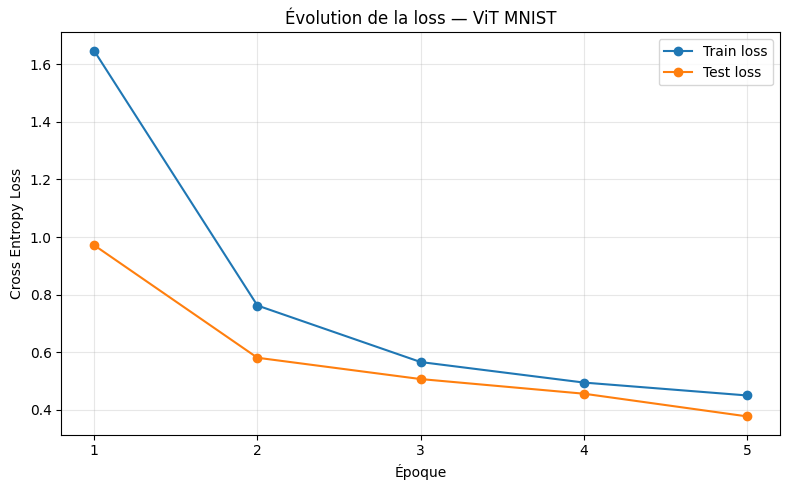

In [12]:
import matplotlib.pyplot as plt
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Train loss")
plt.plot(epochs, test_losses, marker="o", label="Test loss")
plt.title("Évolution de la loss — ViT MNIST")
plt.xlabel("Époque")
plt.ylabel("Cross Entropy Loss")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Évaluation finale sur le test
Après l’entraînement, cette cellule calcule la loss et l’accuracy sur les 10 000 images test.


In [13]:
# Test loop
with torch.no_grad():
    correct, total = 0, 0
    test_loss = 0.0
    for batch in tqdm(test_loader, desc="Testing"):
        x, y = batch
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        y_hat = model(x)
        loss = criterion(y_hat, y)
        test_loss += loss.detach().cpu().item() / len(test_loader)

        correct += torch.sum(torch.argmax(y_hat, dim=1) == y).detach().cpu().item()
        total += len(x)
    print(f"Test loss: {test_loss:.2f}")
    print(f"Test accuracy: {correct / total * 100:.2f}%")


Testing: 100%|██████████| 79/79 [00:01<00:00, 63.30it/s]

Test loss: 0.37
Test accuracy: 87.92%


## 12. Prédictions sur quatre images test
Chaque vignette montre l’image, sa classe réelle et la classe prédite. Le vert indique une prédiction correcte et le rouge une erreur.


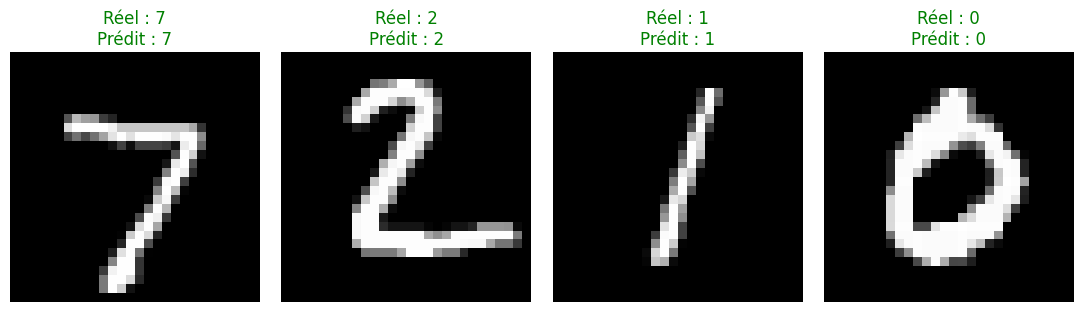

In [14]:
model.eval()
images, labels = next(iter(test_loader))
with torch.no_grad():
    predictions = model(images[:4].to(device, non_blocking=True)).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, image, label, prediction in zip(axes, images[:4], labels[:4], predictions):
    true_label = label.item()
    predicted_label = prediction.item()
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(
        f"Réel : {true_label}\nPrédit : {predicted_label}",
        color="green" if true_label == predicted_label else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

## 13. Conclusion et interprétation

Reportez ici les résultats observés :

- **Test loss :** valeur affichée dans la cellule d’évaluation.
- **Test accuracy :** valeur affichée dans la cellule d’évaluation.
- **Temps d’exécution :** à relever dans la sortie Kaggle.
- **Interprétation :** comparez le résultat du ViT aux modèles de la Partie 1 (CNN, Faster R-CNN, VGG16 et AlexNet).

Le protocole d’origine ne comporte pas d’ensemble de validation ni d’early stopping. La courbe de test sert au suivi ; n’utilisez pas ces valeurs pour ajuster les hyperparamètres.
